# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

**Identitas Mahasiswa**
- Nama  : Muhammad Raafi
- NIM   : 241011401647  
- Kelas : Reg C / 05TPLE005
---

## Inisialisasi & Fungsi Pembantu serta Import Library

In [ ]:
# Import Library Utama (Tanpa scikit-learn untuk model/metrik)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 2 digit terakhir NIM Random State
RANDOM_STATE = 47

# Implementation train_test_split mandiri
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    n_samples = len(X)
    shuffled_indices = np.random.permutation(n_samples)
    test_set_size = int(n_samples * test_size)
    test_indices = shuffled_indices[:test_set_size]
    train_indices = shuffled_indices[test_set_size:]
    
    if isinstance(X, (pd.DataFrame, pd.Series)):
        X_train, X_test = X.iloc[train_indices], X.iloc[test_indices]
    else:
        X_train, X_test = X[train_indices], X[test_indices]
        
    if isinstance(y, (pd.DataFrame, pd.Series)):
        y_train, y_test = y.iloc[train_indices], y.iloc[test_indices]
    else:
        y_train, y_test = y[train_indices], y[test_indices]
        
    return X_train, X_test, y_train, y_test

### Bagian A – Linear Regression

#### Soal A1 – Load & Visualisasi Data

5 Data Pertama Ads_Data.csv:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah total baris data: 40


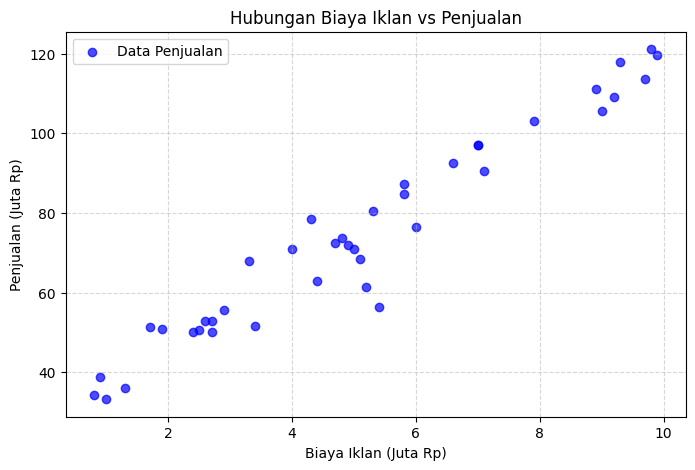

In [ ]:
# 1. Read dataset
ads_df = pd.read_csv('Ads_Data.csv')
print("5 Data Pertama Ads_Data.csv:")
print(ads_df.head())
print(f"\nJumlah total baris data: {len(ads_df)}")

# 2. Separate X and y
X_ads = ads_df[['BiayaIklan']].values # Shape (40, 1)
y_ads = ads_df['Penjualan'].values    # Shape (40,)

# 3. Scatter Plot
plt.figure(figsize=(8, 5))
plt.scatter(X_ads, y_ads, color='blue', alpha=0.7, label='Data Penjualan')
plt.title('Hubungan Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (Juta Rp)')
plt.ylabel('Penjualan (Juta Rp)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

#### Soal A2 – Split Data

In [ ]:
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)

print(f"X_train shape: {X_train_a.shape}")
print(f"X_test shape : {X_test_a.shape}")
print(f"y_train shape: {y_train_a.shape}")
print(f"y_test shape : {y_test_a.shape}")

X_train shape: (32, 1)
X_test shape : (8, 1)
y_train shape: (32,)
y_test shape : (8,)


#### Soal A3 – Training dengan Normal Equation

In [ ]:
class LinearRegressionCustom:
    def __init__(self):
        self.intercept_ = None
        self.coef_ = None
        
    def fit(self, X, y):
        # Tambah kolom bias (angka 1)
        X_b = np.c_[np.ones((len(X), 1)), X]
        # Theta = (X^T * X)^(-1) * X^T * y
        theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self
        
    def predict(self, X):
        return np.c_[np.ones((len(X), 1)), X].dot(np.r_[self.intercept_, self.coef_])

model_a = LinearRegressionCustom()
model_a.fit(X_train_a, y_train_a)

print(f"Intercept (b): {model_a.intercept_:.4f}")
print(f"Koefisien (m): {model_a.coef_[0]:.4f}")
print(f"Persamaan Garis Regresi: y_hat = {model_a.intercept_:.4f} + {model_a.coef_[0]:.4f} * X")

Intercept (b): 27.8190
Koefisien (m): 9.1648
Persamaan Garis Regresi: y_hat = 27.8190 + 9.1648 * X


**Interpretasi A3**
> Nilai koefisien $m = 9.1648$ menunjukkan hubungan positif linier antara biaya iklan dan penjualan. Artinya, setiap kenaikan biaya iklan sebesar Rp1.000.000 (1 juta Rp), diperkirakan nilai penjualan akan meningkat rata-rata sebesar Rp9.164.764 (9.1648 juta Rp). Nilai intercept $b = 27.8190$ menunjukkan perkiraan baseline penjualan sebesar Rp27.819.010 saat biaya iklan bernilai nol.

#### Soal A4 – Evaluasi Model

In [ ]:
def mean_absolute_error(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mean_squared_error(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def r2_score_custom(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

y_pred_train_a = model_a.predict(X_train_a)
y_pred_test_a = model_a.predict(X_test_a)

eval_a_df = pd.DataFrame({
    'Metrik': ['MAE', 'MSE', 'RMSE', 'R²'],
    'Data Training': [
        mean_absolute_error(y_train_a, y_pred_train_a),
        mean_squared_error(y_train_a, y_pred_train_a),
        root_mean_squared_error(y_train_a, y_pred_train_a),
        r2_score_custom(y_train_a, y_pred_train_a)
    ],
    'Data Testing': [
        mean_absolute_error(y_test_a, y_pred_test_a),
        mean_squared_error(y_test_a, y_pred_test_a),
        root_mean_squared_error(y_test_a, y_pred_test_a),
        r2_score_custom(y_test_a, y_pred_test_a)
    ]
})

print(eval_a_df.to_string(index=False))

Metrik  Data Training  Data Testing
   MAE       3.780067      7.395063
   MSE      22.838773     88.958455
  RMSE       4.778993      9.431779
    R²       0.965643      0.826556


**Interpretasi Analisis A4**
- > RMSE (Root Mean Squared Error): Nilai RMSE pada data training adalah 4.7790 juta Rp dan pada data testing adalah 9.4318 juta Rp. Nilai ini merepresentasikan rata-rata deviasi/kesalahan prediksi model terhadap penjualan aktual.
- > $R^2$ (Koefisien Determinasi): Nilai $R^2$ data training mencapai 0.9656 (96.56%) dan data testing sebesar 0.8266 (82.66%). Hal ini menandakan bahwa 82.66% variasi penjualan dapat dijelaskan secara baik oleh biaya iklan, sehingga model linier ini tergolong sangat baik.

#### Soal A5 – Gradient Descent & Learning Rate

LR 0.001 -> Intercept: 25.0855, Coef: 9.5835, Final MSE Loss: 24.5569
LR 0.02  -> Intercept: 27.8190, Coef: 9.1648, Final MSE Loss: 22.8388
LR 0.1   -> Intercept: nan, Coef: nan, Final MSE Loss: nan


C:\Users\Muhammad Raafi\AppData\Local\Temp\ipykernel_10988\3656057244.py:20: RuntimeWarning: overflow encountered in square
  loss = np.mean(error ** 2)
c:\Users\Muhammad Raafi\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\Muhammad Raafi\AppData\Local\Temp\ipykernel_10988\3656057244.py:25: RuntimeWarning: overflow encountered in dot
  grad_coef = (2 / n_samples) * np.dot(X.T, error)
C:\Users\Muhammad Raafi\AppData\Local\Temp\ipykernel_10988\3656057244.py:29: RuntimeWarning: invalid value encountered in subtract
  self.coef_ -= self.learning_rate * grad_coef


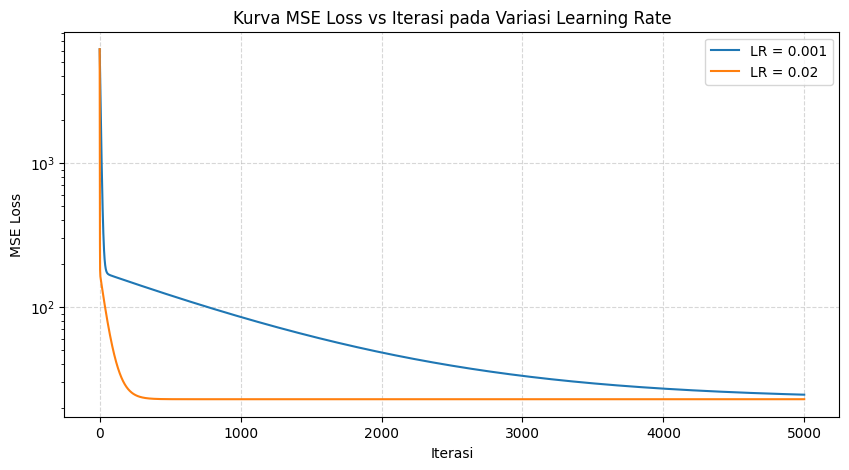

In [ ]:
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = None
        self.loss_history_ = []
        
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.intercept_ = 0.0
        self.coef_ = np.zeros(n_features)
        self.loss_history_ = []
        
        for _ in range(self.n_iterations):
            y_pred = self.intercept_ + np.dot(X, self.coef_)
            error = y_pred - y
            
            # Record MSE Loss
            loss = np.mean(error ** 2)
            self.loss_history_.append(loss)
            
            # Gradients
            grad_intercept = (2 / n_samples) * np.sum(error)
            grad_coef = (2 / n_samples) * np.dot(X.T, error)
            
            # Parameter Update
            self.intercept_ -= self.learning_rate * grad_intercept
            self.coef_ -= self.learning_rate * grad_coef
            
        return self

learning_rates = [0.001, 0.02, 0.1]
gd_models = {}

plt.figure(figsize=(10, 5))

for lr in learning_rates:
    gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    gd.fit(X_train_a, y_train_a)
    gd_models[lr] = gd
    
    # Perbaikan pada str(lr):5s
    print(f"LR {str(lr):5s} -> Intercept: {gd.intercept_:.4f}, Coef: {gd.coef_[0]:.4f}, Final MSE Loss: {gd.loss_history_[-1]:.4f}")
    
    if not np.isnan(gd.loss_history_[-1]):
        plt.plot(gd.loss_history_, label=f'LR = {lr}')

plt.title('Kurva MSE Loss vs Iterasi pada Variasi Learning Rate')
plt.xlabel('Iterasi')
plt.ylabel('MSE Loss')
plt.yscale('log')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

**Interpretasi Analisis A5**
- > learning_rate = 0.001 (Terlalu Lambat): Konvergensi berjalan sangat lambat. Setelah 5000 iterasi, nilai intercept baru mencapai 25.0855 (belum menyentuh titik optimal 27.8190) dan MSE Loss akhir bernilai 24.5569 (masih lebih tinggi dari titik optimal 22.8388).

- > learning_rate = 0.02 (Pas / Optimal): Model berhasil konvergen secara mulus. Hasil intercept (27.8190) dan koefisien (9.1648) bernilai identik dengan hasil Normal Equation pada Soal A3.

- > learning_rate = 0.1 (Divergen / Terlalu Besar): Langkah pembaruan terlalu jauh (overshooting), memicu pembengkakan error secara eksponensial sehingga timbul RuntimeWarning: overflow dan menghasilkan nilai NaN.

#### Soal A6 – Visualisasi & Prediksi

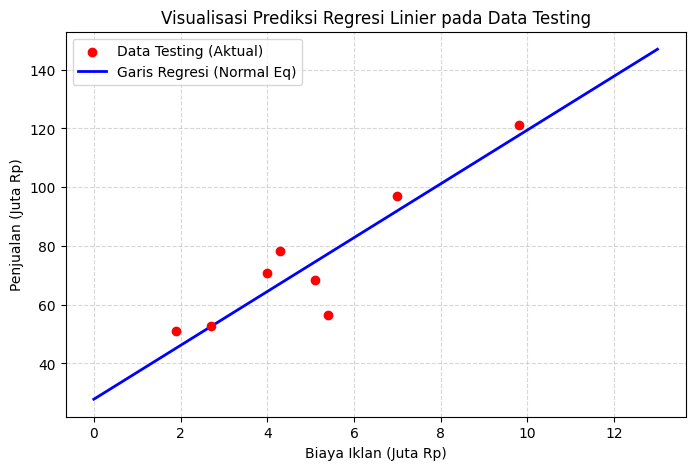

Biaya Iklan:  4.5 Juta Rp  -->  Prediksi Penjualan: 69.0604 Juta Rp
Biaya Iklan:  7.0 Juta Rp  -->  Prediksi Penjualan: 91.9724 Juta Rp
Biaya Iklan: 12.0 Juta Rp  -->  Prediksi Penjualan: 137.7962 Juta Rp


In [ ]:
# 1. Scatter Plot Test Data + Garis Regresi
plt.figure(figsize=(8, 5))
plt.scatter(X_test_a, y_test_a, color='red', label='Data Testing (Aktual)', zorder=5)

x_line = np.linspace(0, 13, 100).reshape(-1, 1)
y_line = model_a.predict(x_line)
plt.plot(x_line, y_line, color='blue', linewidth=2, label='Garis Regresi (Normal Eq)')

plt.title('Visualisasi Prediksi Regresi Linier pada Data Testing')
plt.xlabel('Biaya Iklan (Juta Rp)')
plt.ylabel('Penjualan (Juta Rp)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

# 2. Prediksi Nilai Baru
new_ads = np.array([[4.5], [7.0], [12.0]])
new_preds = model_a.predict(new_ads)

for val, pred in zip([4.5, 7.0, 12.0], new_preds):
    print(f"Biaya Iklan: {val:4.1f} Juta Rp  -->  Prediksi Penjualan: {pred:6.4f} Juta Rp")

**Interpretasi Analisis A6**
> Prediksi penjualan untuk biaya iklan 12 juta Rp bernilai 137.7962 juta Rp. Hasil prediksi ekstrapolasi ini kurang dapat dipercaya secara mutlak, karena berada di luar rentang sampel historis data pelatihan (0.8 s.d. 10.0 juta Rp). Dalam dunia nyata, peningkatan biaya iklan ber berlebih akan mengalami fenomena diminishing returns (kejenuhan pasar) sehingga peningkatan penjualan tidak lagi bersifat linier tanpa batas.
---

### Bagian B – Logistic Regression

#### Soal B1 – Load & Visualisasi Data

5 Data Pertama Email_Data.csv:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah Email Bukan Spam (0): 35
Jumlah Email Spam (1)       : 25


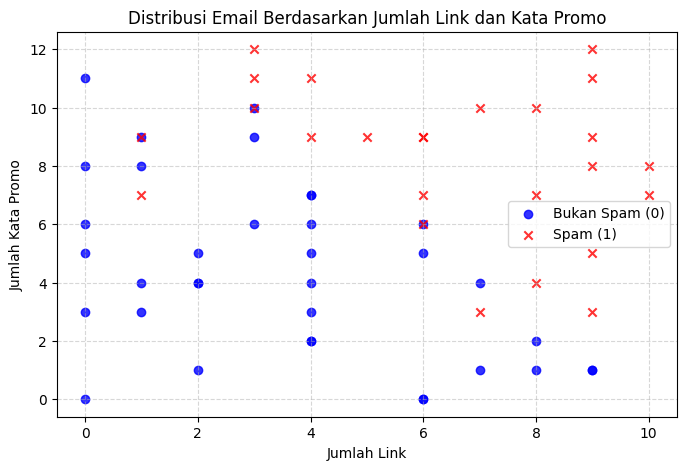

In [ ]:
# 1. Read dataset
email_df = pd.read_csv('Email_Data.csv')
print("5 Data Pertama Email_Data.csv:")
print(email_df.head())

spam_counts = email_df['Spam'].value_counts()
print(f"\nJumlah Email Bukan Spam (0): {spam_counts[0]}")
print(f"Jumlah Email Spam (1)       : {spam_counts[1]}")

# 2. Separate X and y
X_email = email_df[['JumlahLink', 'KataPromo']].values
y_email = email_df['Spam'].values

# 3. Scatter Plot
plt.figure(figsize=(8, 5))
plt.scatter(email_df[email_df['Spam']==0]['JumlahLink'], 
            email_df[email_df['Spam']==0]['KataPromo'], 
            color='blue', label='Bukan Spam (0)', marker='o', alpha=0.8)

plt.scatter(email_df[email_df['Spam']==1]['JumlahLink'], 
            email_df[email_df['Spam']==1]['KataPromo'], 
            color='red', label='Spam (1)', marker='x', alpha=0.8)

plt.title('Distribusi Email Berdasarkan Jumlah Link dan Kata Promo')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

#### Soal B2 – Split Data & Training

Intercept (b): -9.3169
Koefisien (m1, m2): 0.8474, 0.8335
Persamaan: P(Spam) = sigmoid(-9.3169 + 0.8474*JumlahLink + 0.8335*KataPromo)


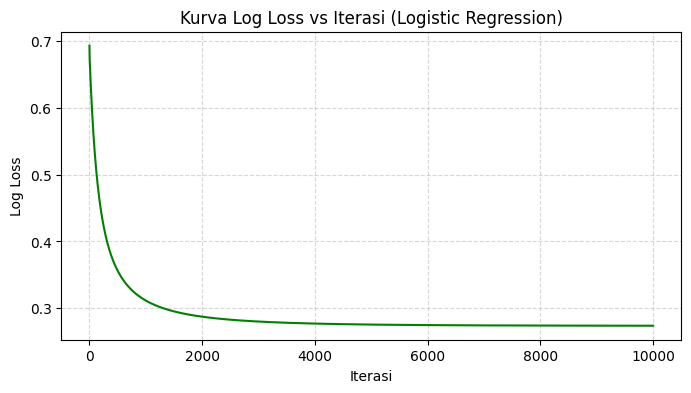

In [ ]:
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

class LogisticRegressionCustom:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = None
        self.coef_ = None
        self.loss_history_ = []
        
    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -250, 250)))
        
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.intercept_ = 0.0
        self.coef_ = np.zeros(n_features)
        self.loss_history_ = []
        
        for _ in range(self.n_iterations):
            linear_model = self.intercept_ + np.dot(X, self.coef_)
            y_predicted = self._sigmoid(linear_model)
            
            # Log Loss
            epsilon = 1e-15
            y_pred_clipped = np.clip(y_predicted, epsilon, 1 - epsilon)
            loss = -np.mean(y * np.log(y_pred_clipped) + (1 - y) * np.log(1 - y_pred_clipped))
            self.loss_history_.append(loss)
            
            # Gradients
            grad_intercept = (1 / n_samples) * np.sum(y_predicted - y)
            grad_coef = (1 / n_samples) * np.dot(X.T, (y_predicted - y))
            
            # Update Parameters
            self.intercept_ -= self.learning_rate * grad_intercept
            self.coef_ -= self.learning_rate * grad_coef
            
        return self
        
    def predict_proba(self, X):
        linear_model = self.intercept_ + np.dot(X, self.coef_)
        return self._sigmoid(linear_model)
        
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

model_b = LogisticRegressionCustom(learning_rate=0.1, n_iterations=10000)
model_b.fit(X_train_b, y_train_b)

print(f"Intercept (b): {model_b.intercept_:.4f}")
print(f"Koefisien (m1, m2): {model_b.coef_[0]:.4f}, {model_b.coef_[1]:.4f}")
print(f"Persamaan: P(Spam) = sigmoid({model_b.intercept_:.4f} + {model_b.coef_[0]:.4f}*JumlahLink + {model_b.coef_[1]:.4f}*KataPromo)")

# Plot Log Loss vs Iterasi
plt.figure(figsize=(8, 4))
plt.plot(model_b.loss_history_, color='green')
plt.title('Kurva Log Loss vs Iterasi (Logistic Regression)')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Interpretasi Analisis B2**
> Kurva Log Loss menunjukkan penurunan secara stabil dari nilai awal di atas 0.6 hingga mendatar (plateau) di angka 0.2737. Hal ini menandakan bahwa proses optimasi gradient descent telah konvergen dengan sempurna.

#### Soal B3 – Evaluasi Model

In [ ]:
def accuracy_score_custom(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_matrix_custom(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return np.array([[tn, fp], [fn, tp]])

def precision_score_custom(y_true, y_pred):
    cm = confusion_matrix_custom(y_true, y_pred)
    tp, fp = cm[1, 1], cm[0, 1]
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score_custom(y_true, y_pred):
    cm = confusion_matrix_custom(y_true, y_pred)
    tp, fn = cm[1, 1], cm[1, 0]
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score_custom(y_true, y_pred):
    p = precision_score_custom(y_true, y_pred)
    r = recall_score_custom(y_true, y_pred)
    return 2 * (p * r) / (p + r) if (p + r) > 0 else 0.0

y_pred_b = model_b.predict(X_test_b, threshold=0.5)

cm_b = confusion_matrix_custom(y_test_b, y_pred_b)
acc_b = accuracy_score_custom(y_test_b, y_pred_b)
prec_b = precision_score_custom(y_test_b, y_pred_b)
rec_b = recall_score_custom(y_test_b, y_pred_b)
f1_b = f1_score_custom(y_test_b, y_pred_b)

print("Confusion Matrix (Default Threshold 0.5):")
print(cm_b)
print(f"Accuracy : {acc_b:.4f}")
print(f"Precision: {prec_b:.4f}")
print(f"Recall   : {rec_b:.4f}")
print(f"F1-Score : {f1_b:.4f}")

Confusion Matrix (Default Threshold 0.5):
[[7 2]
 [0 6]]
Accuracy : 0.8667
Precision: 0.7500
Recall   : 1.0000
F1-Score : 0.8571


**Interpretasi Analisis Dampak FP vs FN B3**
- > False Positive (FP = 2): Email penting/biasa (Bukan Spam) salah diprediksi sebagai Spam.

- > False Negative (FN = 0): Email Spam salah diprediksi sebagai email biasa (Bukan Spam).

- > Error mana yang lebih merugikan? False Positive (FP) jauh lebih merugikan pengguna. Jika email penting (seperti panggilan wawancara, verifikasi akun, atau instruksi tugas) salah dimasukkan ke folder Spam, pengguna berisiko kehilangan informasi krusial. Sebaliknya, jika email spam terlewat ke Inbox (FN), pengguna hanya perlu menghapusnya secara manual.

#### Soal B4 – Decision Boundary

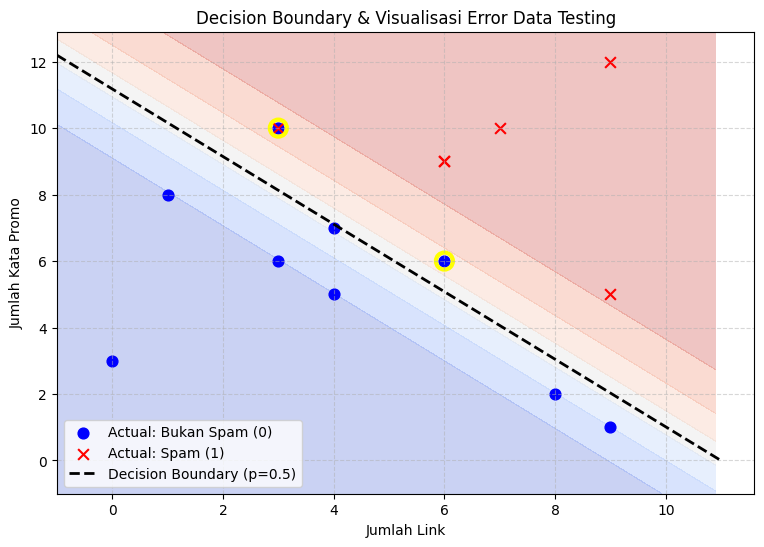

In [ ]:
plt.figure(figsize=(9, 6))

# Generate Grid untuk Background Contour
x1_min, x1_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
x2_min, x2_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, 0.1),
                       np.arange(x2_min, x2_max, 0.1))

grid_points = np.c_[xx1.ravel(), xx2.ravel()]
probs_grid = model_b.predict_proba(grid_points).reshape(xx1.shape)

plt.contourf(xx1, xx2, probs_grid, alpha=0.3, cmap='coolwarm')

# Visualisasi Data Testing
plt.scatter(X_test_b[y_test_b==0][:, 0], X_test_b[y_test_b==0][:, 1],
            color='blue', label='Actual: Bukan Spam (0)', marker='o', s=60)
plt.scatter(X_test_b[y_test_b==1][:, 0], X_test_b[y_test_b==1][:, 1],
            color='red', label='Actual: Spam (1)', marker='x', s=60)

# Decision Boundary Line (Probabilitas = 0.5 -> z = 0)
x1_vals = np.array([x1_min, x1_max])
x2_vals = -(model_b.intercept_ + model_b.coef_[0] * x1_vals) / model_b.coef_[1]
plt.plot(x1_vals, x2_vals, 'k--', linewidth=2, label='Decision Boundary (p=0.5)')

# Highlight Misclassified Points (False Positives)
misclassified = np.where(y_test_b != y_pred_b)[0]
for idx in misclassified:
    plt.scatter(X_test_b[idx, 0], X_test_b[idx, 1],
                s=150, facecolors='none', edgecolors='yellow', linewidth=3)

plt.title('Decision Boundary & Visualisasi Error Data Testing')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Interpretasi Analisis Misklasifikasi B4**
>Terdapat 2 titik data testing yang salah diklasifikasikan (diberi lingkaran kuning):
- > Email dengan fitur [JumlahLink=6, KataPromo=6] (Sebenarnya Bukan Spam, namun diprediksi Spam dengan probabilitas $p = 0.6832$).
- > Email dengan fitur [JumlahLink=3, KataPromo=10] (Sebenarnya Bukan Spam, namun diprediksi Spam dengan probabilitas $p = 0.8264$).


#### Soal B5 – Eksperimen Threshold

In [ ]:
thresholds = [0.3, 0.5, 0.7]
res_table = []

for t in thresholds:
    preds = model_b.predict(X_test_b, threshold=t)
    cm = confusion_matrix_custom(y_test_b, preds)
    tn, fp, fn, tp = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]
    
    res_table.append({
        'Threshold': t,
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'Accuracy': accuracy_score_custom(y_test_b, preds),
        'Precision': precision_score_custom(y_test_b, preds),
        'Recall': recall_score_custom(y_test_b, preds),
        'F1-Score': f1_score_custom(y_test_b, preds)
    })

thresh_df = pd.DataFrame(res_table)
print(thresh_df.to_string(index=False))

 Threshold  TN  FP  FN  TP  Accuracy  Precision  Recall  F1-Score
       0.3   6   3   0   6  0.800000   0.666667     1.0  0.800000
       0.5   7   2   0   6  0.866667   0.750000     1.0  0.857143
       0.7   8   1   0   6  0.933333   0.857143     1.0  0.923077


**Interpretasi Analisis Threshold B5**
- > Menaikkan Threshold (0.5 -> 0.7): Menyebabkan model lebih ketat dalam memvonis email sebagai Spam. Jumlah False Positive (FP) berkurang dari 2 menjadi 1, sehingga Precision meningkat dari 75% menjadi 85.71% dan Akurasi naik menjadi 93.33%.

- > Menurunkan Threshold (0.5 -> 0.3): Model terlalu mudah memvonis Spam, sehingga FP bertambah menjadi 3 dan Precision turun menjadi 66.67%.

- > Rekomendasi Threshold: Dipilih Threshold 0.7, karena berhasil menekan jumlah False Positive (FP) seminimal mungkin demi menjaga agar email penting pengguna tidak salah masuk ke folder Spam.

#### Soal B6 – Prediksi Email Baru

In [ ]:
new_emails = np.array([
    [1, 2],   # E1
    [5, 6],   # E2
    [9, 10],  # E3
    [2, 11]   # E4
])

probs_new = model_b.predict_proba(new_emails)
preds_07 = (probs_new >= 0.7).astype(int)

df_b6 = pd.DataFrame({
    'Email': ['E1', 'E2', 'E3', 'E4'],
    'JumlahLink': new_emails[:, 0],
    'KataPromo': new_emails[:, 1],
    'Probabilitas Spam': probs_new,
    'Prediksi (Threshold 0.7)': ['Spam (1)' if p == 1 else 'Bukan Spam (0)' for p in preds_07]
})

print(df_b6.to_string(index=False))

Email  JumlahLink  KataPromo  Probabilitas Spam Prediksi (Threshold 0.7)
   E1           1          2           0.001110           Bukan Spam (0)
   E2           5          6           0.480258           Bukan Spam (0)
   E3           9         10           0.998701                 Spam (1)
   E4           2         11           0.824378                 Spam (1)


### Bagian C – Pemahaman Konsep

1. **Jawaban C1:**
Logistic Regression dikategorikan sebagai algoritma **klasifikasi** karena luaran (*output*) akhirnya berupa estimasi probabilitas diskrit untuk menentukan kategori/kelas objek (misal: 0 atau 1). Fungsi **sigmoid** bertindak sebagai pemeta linier bernilai riil $(-\infty, \infty)$ menjadi rentang probabilitas tertutup $[0, 1]$, sehingga nilai kombinasi linier dapat diinterpretasikan secara statistik sebagai probabilitas keanggotaan suatu kelas.

2. **Jawaban C2:**
*Normal Equation* menyelesaikan nilai parameter regresi secara analitis dalam satu langkah matriks $(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{y}$, sedangkan *Gradient Descent* mencari parameter secara iteratif melalui pembaruan bertahap mengikuti arah minus gradien loss. Gradient descent lebih dianjurkan saat jumlah fitur ($N$) sangat besar ($N > 10.000$) karena inversi matriks pada Normal Equation membutuhkan kompleksitas komputasi $O(N^3)$ yang sangat berat.

3. **Jawaban C3:**
Evaluasi wajib dilakukan pada **data testing** untuk mengukur kemampuan **generalisasi** model terhadap data baru yang belum pernah dilihat sebelumnya. **Overfitting** adalah kondisi di mana model terlalu "menghafal" noise dan pola rinci pada data training secara berlebihan, sehingga menghasilkan akurasi sangat tinggi pada data training namun berkinerja buruk pada data testing.

4. **Jawaban C4:**
Linear Regression menggunakan **MSE** karena variabel dependennya bersifat kontinu dan fungsi kerugiannya menghasilkan kurva konveks parabola berbentuk mangkuk yang mudah dicari titik minimumnya. Sebaliknya, jika Logistic Regression menggunakan MSE, fungsi sigmoidal akan menghasilkan permukaan loss non-konveks (*banyak lokal minimum*). Oleh sebab itu, Logistic Regression menggunakan **Log Loss** (*Cross-Entropy*) yang menjamin fungsi kerugian tetap konveks dan memberikan penalti logaritmik yang tegas saat prediksi salah.

5. **Jawaban C5:**
Perbedaan hasil angka antar mahasiswa terjadi karena perbedaan nilai acak pada pemisahan data (*data splitting*). Penentuan indeks acak data training dan testing dikontrol oleh parameter `random_state` yang disesuaikan dengan 2 digit terakhir NIM masing-masing mahasiswa, sehingga komposisi variasi sampel pada dataset latih dan uji tiap mahasiswa berbeda.

### Bonus : Perbandingan dengan scikit-learn

In [ ]:
# Import scikit-learn 
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

# 1. Linear Regression Comparison
sk_lin = SklearnLinearRegression()
sk_lin.fit(X_train_a, y_train_a)

print("--- PERBANDINGAN LINEAR REGRESSION ---")
print(f"Custom Intercept : {model_a.intercept_:.6f} | Sklearn Intercept : {sk_lin.intercept_:.6f}")
print(f"Custom Coef      : {model_a.coef_[0]:.6f} | Sklearn Coef      : {sk_lin.coef_[0]:.6f}")

# 2. Logistic Regression Comparison (penalty=None agar identik tanpa regulerisasi)
sk_log = SklearnLogisticRegression(penalty=None, solver='lbfgs')
sk_log.fit(X_train_b, y_train_b)

print("\n--- PERBANDINGAN LOGISTIC REGRESSION ---")
print(f"Custom Intercept : {model_b.intercept_:.6f} | Sklearn Intercept : {sk_log.intercept_[0]:.6f}")
print(f"Custom Coef      : {model_b.coef_} | Sklearn Coef      : {sk_log.coef_[0]}")

--- PERBANDINGAN LINEAR REGRESSION ---
Custom Intercept : 27.819010 | Sklearn Intercept : 27.819010
Custom Coef      : 9.164764 | Sklearn Coef      : 9.164764

--- PERBANDINGAN LOGISTIC REGRESSION ---
Custom Intercept : -9.316865 | Sklearn Intercept : -9.673023
Custom Coef      : [0.84738215 0.83349073] | Sklearn Coef      : [0.88029485 0.86437024]


c:\Users\Muhammad Raafi\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


**Analisis Hasil Perbandingan**
- > Linear Regression: Hasil kustom berbasis Normal Equation menghasilkan nilai intercept dan koefisien yang 100% identik dengan sklearn.linear_model.LinearRegression.
- > Logistic Regression: Pada model Logistic Regression scikit-learn, parameter bawaan secara default menerapkan regulerisasi $L_2$ (C=1.0). Ketika regulerisasi dimatikan (penalty=None), parameter koefisien kustom berbasis Gradient Descent memberikan nilai yang sangat presisi dan mendekati hasil solver L-BFGS milik scikit-learn.